In [ ]:

%pip install pandas numpy matplotlib seaborn ipykernel


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

from pathlib import Path

# Find the cleaned dataset
filename = "ecommerce_logistics_cleaned.csv"
base = Path.cwd()

possible_paths = [
    base / "Dataset" / "Cleaned" / filename,
    base.parent / "Dataset" / "Cleaned" / filename,
    base / "E-Commerce and Logistics delivery Analysis" / "Dataset" / "Cleaned" / filename,
]

file_path = next((p for p in possible_paths if p.is_file()), None)

if file_path is None:
    raise FileNotFoundError("Cleaned dataset not found. Check its folder location.")

# Load the cleaned dataset
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Total Rows: 180519
Total Columns: 54


,Customer Id,Order Id,order date (DateOrders),order_year,order_weekday,Order Item Id,shipping date (DateOrders),processing_days,Days for shipping (real),Days for shipment (scheduled),...,Product Category Id,Product Image,Product Name,Product Price,Shipping Mode,delay_days,is_late,is_cancelled,kpi_eligible,Type
0,6428,18950,2015-10-04 14:40:00.000,2015,Sunday,47390,2015-10-10 14:40:00.000,6,6,2,...,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,4,1,0,1,DEBIT
1,1851,15751,2015-08-18 21:55:00.000,2015,Tuesday,39375,2015-08-20 21:55:00.000,2,2,2,...,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,0,0,0,1,DEBIT
2,3012,14965,2015-08-07 10:33:00.000,2015,Friday,37479,2015-08-13 10:33:00.000,6,6,2,...,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,4,1,0,1,DEBIT
3,6365,17810,2015-09-17 23:17:00.000,2015,Thursday,44492,2015-09-23 23:17:00.000,6,6,2,...,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,4,1,0,1,DEBIT
4,8098,14730,2015-08-04 00:13:00.000,2015,Tuesday,36852,2015-08-10 00:13:00.000,6,6,2,...,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,4,1,0,1,DEBIT


In [ ]:

# STEP 9: Data Overview and Quality Check

print("DATASET INFORMATION")
print("-" * 40)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes.to_string())

print("\nMISSING VALUES (TOP 15):")
missing = df.isnull().sum().sort_values(
    ascending=False
)
print(missing.head(15))

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nDELIVERY STATUS:")
print(df["is_late"].value_counts(dropna=False))

print("\nCANCELLED STATUS:")
print(df["is_cancelled"].value_counts(dropna=False))

print("\nKPI ELIGIBILITY:")
print(df["kpi_eligible"].value_counts(dropna=False))


In [ ]:

# STEP 10: Delivery Performance Analysis

# Select records eligible for KPI analysis
delivery_df = df[df["kpi_eligible"] == 1].copy()

# Check delivery status consistency within each order
status_check = delivery_df.groupby("Order Id")["is_late"].nunique()
print("Orders with mixed delivery statuses:",
      (status_check > 1).sum())

# One record per order to avoid counting order items multiple times
orders_df = delivery_df.drop_duplicates(subset="Order Id")

# Calculate delivery counts
delivery_counts = (
    orders_df["is_late"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

on_time = delivery_counts[0]
late = delivery_counts[1]
total = delivery_counts.sum()

late_percentage = (late / total) * 100 if total else 0

print("Total Eligible Orders:", total)
print("Not Late Orders:", on_time)
print("Late Orders:", late)
print(f"Late Delivery Percentage: {late_percentage:.2f}%")

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Not Late", "Late"],
    [on_time, late],
    color=["seagreen", "tomato"]
)

plt.title("Delivery Performance Analysis")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.savefig(
    visualizations_dir / "01_delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [ ]:

# STEP 11: Shipping Mode vs Late Delivery Analysis

# Group unique eligible orders by shipping mode
shipping_analysis = orders_df.groupby(
    "Shipping Mode"
).agg(
    total_orders=("Order Id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

# Calculate late delivery percentage
shipping_analysis["late_percentage"] = (
    shipping_analysis["late_orders"] /
    shipping_analysis["total_orders"] * 100
)

# Sort by highest late delivery rate
shipping_analysis = shipping_analysis.sort_values(
    by="late_percentage",
    ascending=False
)

print("SHIPPING MODE ANALYSIS")
display(shipping_analysis.round(2))

# Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=shipping_analysis,
    x="Shipping Mode",
    y="late_percentage"
)

plt.title("Late Delivery Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Percentage (%)")
plt.ylim(0, 100)

# Display percentages on bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [ ]:

# STEP 12: Delivery Delay Days Analysis

# Use unique KPI-eligible orders
delay_df = orders_df.copy()

# Convert delay days into numeric values
delay_df["delay_days"] = pd.to_numeric(
    delay_df["delay_days"],
    errors="coerce"
)

# Verify delay flag consistency
mismatch = (
    (delay_df["delay_days"] > 0).astype(int)
    != delay_df["is_late"]
).sum()

print("Delay Flag Mismatches:", mismatch)

# Select late deliveries
late_df = delay_df[
    (delay_df["is_late"] == 1) &
    (delay_df["delay_days"].notna())
].copy()

# Calculate delay statistics
print("\nDELIVERY DELAY STATISTICS")

print("Total Late Orders:", len(late_df))

print(
    "Average Delay:",
    round(late_df["delay_days"].mean(), 2),
    "days"
)

print(
    "Median Delay:",
    round(late_df["delay_days"].median(), 2),
    "days"
)

print(
    "Maximum Delay:",
    late_df["delay_days"].max(),
    "days"
)

# Delay distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=late_df,
    x="delay_days",
    discrete=True,
    color="steelblue"
)

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Late Orders")

plt.tight_layout()
plt.show()


In [ ]:

# STEP 13: Actual vs Scheduled Shipping Days

# Analyze shipping performance by mode
shipping_days = delay_df.groupby("Shipping Mode").agg(
    total_orders=("Order Id", "nunique"),
    avg_actual_days=("Days for shipping (real)", "mean"),
    avg_scheduled_days=("Days for shipment (scheduled)", "mean"),
    avg_delay_days=("delay_days", "mean"),
    late_rate=("is_late", "mean")
)

shipping_days["late_rate"] *= 100

print("SHIPPING PERFORMANCE COMPARISON")
display(shipping_days.round(2))

# Actual vs Scheduled comparison chart
shipping_days[
    ["avg_actual_days", "avg_scheduled_days"]
].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange"]
)

plt.title("Actual vs Scheduled Shipping Days")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=0)
plt.legend(["Actual Days", "Scheduled Days"])
plt.tight_layout()
plt.show()


In [ ]:

# STEP 14: Monthly Order Trends Analysis

# Select one record per order
order_trends = df.drop_duplicates(
    subset="Order Id"
).copy()

# Convert order date into datetime
order_trends["order_date"] = pd.to_datetime(
    order_trends["order date (DateOrders)"],
    format="mixed",
    errors="coerce"
)

# Check date conversion
print("Invalid Dates:",
      order_trends["order_date"].isna().sum())

# Remove records with invalid dates
order_trends = order_trends.dropna(
    subset=["order_date"]
)

# Extract year and month
order_trends["order_month"] = (
    order_trends["order_date"]
    .dt.to_period("M")
)

# Count unique orders each month
monthly_orders = (
    order_trends.groupby("order_month")["Order Id"]
    .nunique()
    .sort_index()
)

print("\nMONTHLY ORDER TRENDS")
display(monthly_orders.to_frame("total_orders"))

# Plot monthly order trends
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("Monthly E-Commerce Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 15: Customer Order Analysis

# Use unique orders from Step 14
customer_orders = (
    order_trends.groupby("Customer Id")["Order Id"]
    .nunique()
)

# Customer statistics
total_customers = customer_orders.shape[0]
one_time_customers = (customer_orders == 1).sum()
repeat_customers = (customer_orders > 1).sum()

repeat_percentage = (
    repeat_customers / total_customers * 100
    if total_customers else 0
)

print("CUSTOMER ORDER ANALYSIS")
print("--------------------------")

print("Total Unique Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print(
    f"Repeat Customer Percentage: {repeat_percentage:.2f}%"
)

print(
    "Average Orders Per Customer:",
    round(customer_orders.mean(), 2)
)

# Group customers by number of orders
customer_groups = pd.cut(
    customer_orders,
    bins=[0, 1, 3, 5, 10, float("inf")],
    labels=["1", "2-3", "4-5", "6-10", "11+"]
)

group_counts = (
    customer_groups.value_counts()
    .sort_index()
)

print("\nCUSTOMER ORDER DISTRIBUTION")
display(group_counts.to_frame("Customers"))

# Visualization
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=group_counts.index.astype(str),
    y=group_counts.values,
    color="steelblue"
)

plt.title("Customer Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [ ]:

# STEP 16: Product Category Sales Analysis

# Identify category column
category_col = (
    "Category Name"
    if "Category Name" in df.columns
    else "Product Category Id"
)

# Check net sales column
if "Order Item Total" not in df.columns:
    raise KeyError(
        "Order Item Total column missing. "
        "Check available sales columns."
    )

# Use item-level records for sales analysis
sales_df = df.copy()

sales_df["Order Item Total"] = pd.to_numeric(
    sales_df["Order Item Total"],
    errors="coerce"
)

# Calculate category-wise sales
category_sales = (
    sales_df.groupby(category_col)
    .agg(
        total_sales=("Order Item Total", "sum"),
        order_items=("Order Item Id", "count")
    )
    .sort_values("total_sales", ascending=False)
    .head(10)
)

print("TOP 10 PRODUCT CATEGORIES BY SALES")
display(category_sales.round(2))

# Create visualization
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=category_sales["total_sales"],
    y=category_sales.index.astype(str),
    color="steelblue"
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()


In [ ]:

# STEP 17: Product Category Profitability Analysis

profit_df = df.copy()

profit_df["Benefit per order"] = pd.to_numeric(
    profit_df["Benefit per order"],
    errors="coerce"
)

profit_df = profit_df.dropna(
    subset=["Benefit per order"]
)

# Analyze profitability indicators for top sales categories
category_profit = (
    profit_df.groupby(category_col)
    .agg(
        records=("Benefit per order", "size"),
        avg_benefit=("Benefit per order", "mean"),
        negative_benefit_pct=(
            "Benefit per order",
            lambda x: (x < 0).mean() * 100
        )
    )
    .reindex(category_sales.index)
)

print("CATEGORY PROFITABILITY ANALYSIS")
display(category_profit.round(2))

# Visualize negative benefit percentage
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=category_profit["negative_benefit_pct"],
    y=category_profit.index.astype(str),
    color="indianred"
)

plt.title("Negative Benefit Rate by Product Category")
plt.xlabel("Records with Negative Benefit (%)")
plt.ylabel("Product Category")

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.1f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        va="center",
        ha="left",
        xytext=(4, 0),
        textcoords="offset points"
    )

plt.xlim(
    0,
    max(10, category_profit["negative_benefit_pct"].max() * 1.2)
)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 18: Regional Sales & Delivery Analysis

# Identify region column
region_col = next(
    (
        c for c in ["Order Region", "Order Country", "Order State"]
        if c in df.columns
    ),
    None
)

if region_col is None:
    raise KeyError("Region column not found.")

print("Using Region Column:", region_col)

# PART 1: Regional Sales Analysis
regional_sales_df = df.copy()

regional_sales_df["Order Item Total"] = pd.to_numeric(
    regional_sales_df["Order Item Total"],
    errors="coerce"
)

regional_sales = (
    regional_sales_df.groupby(region_col)["Order Item Total"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 REGIONS BY SALES")
display(regional_sales.to_frame("Total Sales").round(2))

# Sales Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=regional_sales.values,
    y=regional_sales.index,
    color="steelblue"
)

plt.title("Top 10 Regions by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

# PART 2: Region-wise Delivery Performance
regional_delivery = (
    orders_df.groupby(region_col)
    .agg(
        total_orders=("Order Id", "nunique"),
        late_orders=("is_late", "sum")
    )
)

regional_delivery["late_rate"] = (
    regional_delivery["late_orders"] /
    regional_delivery["total_orders"] * 100
)

# Focus on the top 10 sales regions
regional_delivery = regional_delivery.reindex(
    regional_sales.index
)

print("\nREGIONAL DELIVERY PERFORMANCE")
display(regional_delivery.round(2))

# Late Delivery Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=regional_delivery["late_rate"],
    y=regional_delivery.index,
    color="indianred"
)

plt.title("Late Delivery Rate in Top Sales Regions")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Region")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 19: Correlation Analysis

# Select delivery-related numerical columns
selected_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "processing_days",
    "delay_days",
    "is_late"
]

# Check available columns
available_columns = [
    col for col in selected_columns
    if col in orders_df.columns
]

# Use unique KPI-eligible orders
correlation_df = orders_df[
    available_columns
].copy()

# Convert columns to numeric
for col in available_columns:
    correlation_df[col] = pd.to_numeric(
        correlation_df[col],
        errors="coerce"
    )

# Calculate Spearman correlation
correlation_matrix = correlation_df.corr(
    method="spearman"
)

print("DELIVERY CORRELATION MATRIX")
display(correlation_matrix.round(2))

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Delivery Performance Correlation Heatmap")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Correlations with late delivery
print("\nCORRELATION WITH LATE DELIVERY")

display(
    correlation_matrix["is_late"]
    .drop("is_late")
    .sort_values(ascending=False)
)


In [ ]:

# STEP 20: Data Redundancy Verification

# Select columns
check_df = orders_df[
    ["Days for shipping (real)", "processing_days"]
].copy()

# Convert to numeric
for col in check_df.columns:
    check_df[col] = pd.to_numeric(
        check_df[col],
        errors="coerce"
    )

# Exclude missing values
valid_df = check_df.dropna()

# Compare both columns
matching = (
    valid_df["Days for shipping (real)"]
    == valid_df["processing_days"]
).sum()

different = len(valid_df) - matching

print("DATA REDUNDANCY CHECK")
print("-------------------------")
print("Records Compared:", len(valid_df))
print("Matching Records:", matching)
print("Different Records:", different)

print(
    "Match Percentage:",
    round(matching / len(valid_df) * 100, 2)
    if len(valid_df) else 0,
    "%"
)

print("\nSAMPLE COMPARISON")
display(valid_df.head(10))


In [ ]:

# STEP 21: Generate Final EDA Findings Report

from pathlib import Path

# Locate existing EDA folder
project_root = file_path.resolve().parents[2]
eda_folder = project_root / "EDA (Python-scripts)"

eda_folder.mkdir(parents=True, exist_ok=True)

# Calculate summary metrics
total_orders = len(orders_df)
late_orders = int(orders_df["is_late"].sum())
late_rate = late_orders / total_orders * 100

avg_delay = late_df["delay_days"].mean()

total_customers = len(customer_orders)
repeat_customers = int((customer_orders > 1).sum())
repeat_rate = repeat_customers / total_customers * 100

highest_risk_region = regional_delivery["late_rate"].idxmax()
highest_region_rate = regional_delivery["late_rate"].max()

top_category = category_sales.index[0]

# Prepare report
report = f"""
# E-Commerce & Logistics Performance Analysis
## Exploratory Data Analysis Findings

### 1. Dataset Overview
- Total Records: {len(df):,}
- Total Columns: {len(df.columns)}
- KPI-Eligible Unique Orders: {total_orders:,}

### 2. Delivery Performance
- Late Orders: {late_orders:,}
- Late Delivery Rate: {late_rate:.2f}%
- Average Delay Among Late Orders: {avg_delay:.2f} days

### 3. Shipping Mode Analysis
- First Class Late Rate: 100%
- Second Class Late Rate: 80.09%
- Same Day Late Rate: 48.51%
- Standard Class Late Rate: 39.76%

### 4. Customer Analysis
- Total Unique Customers: {total_customers:,}
- Repeat Customers: {repeat_customers:,}
- Repeat Customer Rate: {repeat_rate:.2f}%

### 5. Product Category Analysis
- Highest Sales Category: {top_category}

### 6. Regional Delivery Analysis
- Highest Late Rate Among Top Sales Regions:
  {highest_risk_region} ({highest_region_rate:.2f}%)

### 7. Data Redundancy Findings
- processing_days matches actual shipping days
  in all 28,965 compared eligible unique orders.
- Avoid treating both fields as independent features.

### 8. Business Recommendations
1. Investigate First Class and Second Class delivery targets.
2. Improve on-time delivery performance.
3. Investigate regions with higher late delivery rates.
4. Review categories with negative benefit records.
5. Analyze repeat purchasing and customer retention.

### 9. Analysis Notes
- Delivery KPIs use unique KPI-eligible orders.
- Sales analysis uses order-item records.
- Correlation does not establish causation.
- Shipping-mode results should be checked against
  scheduled delivery definitions.
"""

# Save Markdown report
report_path = eda_folder / "EDA_Findings.md"

report_path.write_text(report, encoding="utf-8")

print("EDA Findings Report Generated Successfully!")
print("Saved Location:", report_path)


In [ ]:

# STEP 22: Create Visualization Folder

from pathlib import Path

visualizations_dir = (
    project_root / "EDA (Python-scripts)" / "visualizations"
)

visualizations_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Visualization folder created successfully!")
print("Location:", visualizations_dir)


In [ ]:

# STEP 24: AUTOMATIC EXPORT OF ALL REMAINING EDA GRAPHS

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create or locate visualization folder
visualizations_dir = (
    Path(file_path).resolve().parents[2]
    / "EDA (Python-scripts)"
    / "visualizations"
)

visualizations_dir.mkdir(parents=True, exist_ok=True)

# Helper function for exporting charts
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        visualizations_dir / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.close()
    print(f"Saved: {filename}")


# -------------------------------------------------
# GRAPH 02: SHIPPING MODE ANALYSIS
# -------------------------------------------------

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=shipping_analysis,
    x="Shipping Mode",
    y="late_percentage",
    color="steelblue"
)

plt.title("Late Delivery Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Rate (%)")
plt.ylim(0, 110)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

save_chart("02_shipping_mode_analysis.png")


# -------------------------------------------------
# GRAPH 03: DELIVERY DELAY DISTRIBUTION
# -------------------------------------------------

plt.figure(figsize=(10, 6))

sns.histplot(
    data=late_df,
    x="delay_days",
    discrete=True,
    color="steelblue"
)

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Late Orders")

save_chart("03_delivery_delay_distribution.png")


# -------------------------------------------------
# GRAPH 04: ACTUAL VS SCHEDULED SHIPPING
# -------------------------------------------------

shipping_days[
    ["avg_actual_days", "avg_scheduled_days"]
].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange"]
)

plt.title("Actual vs Scheduled Shipping Days")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=0)
plt.legend(["Actual Days", "Scheduled Days"])

save_chart("04_actual_vs_scheduled.png")


# -------------------------------------------------
# GRAPH 05: MONTHLY ORDER TRENDS
# -------------------------------------------------

plt.figure(figsize=(13, 6))

plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker="o",
    color="royalblue",
    linewidth=2
)

plt.title("Monthly E-Commerce Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)
plt.grid(alpha=0.3)

save_chart("05_monthly_order_trends.png")


# -------------------------------------------------
# GRAPH 06: CUSTOMER ORDER ANALYSIS
# -------------------------------------------------

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=group_counts.index.astype(str),
    y=group_counts.values,
    color="steelblue"
)

plt.title("Customer Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

save_chart("06_customer_analysis.png")


# -------------------------------------------------
# GRAPH 07: PRODUCT CATEGORY SALES
# -------------------------------------------------

plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_sales["total_sales"],
    y=category_sales.index.astype(str),
    color="steelblue"
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")

save_chart("07_category_sales.png")


# -------------------------------------------------
# GRAPH 08: PROFITABILITY ANALYSIS
# -------------------------------------------------

plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_profit["negative_benefit_pct"],
    y=category_profit.index.astype(str),
    color="indianred"
)

plt.title("Negative Benefit Rate by Product Category")
plt.xlabel("Records with Negative Benefit (%)")
plt.ylabel("Product Category")

save_chart("08_profitability_analysis.png")


# -------------------------------------------------
# GRAPH 09: REGIONAL SALES
# -------------------------------------------------

plt.figure(figsize=(12, 7))

sns.barplot(
    x=regional_sales.values,
    y=regional_sales.index.astype(str),
    color="steelblue"
)

plt.title("Top 10 Regions by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Region")

save_chart("09_regional_sales.png")


# -------------------------------------------------
# GRAPH 10: REGIONAL DELIVERY PERFORMANCE
# -------------------------------------------------

plt.figure(figsize=(12, 7))

sns.barplot(
    x=regional_delivery["late_rate"],
    y=regional_delivery.index.astype(str),
    color="indianred"
)

plt.title("Late Delivery Rate in Top Sales Regions")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Region")
plt.xlim(0, 100)

save_chart("10_regional_delivery.png")


# -------------------------------------------------
# GRAPH 11: CORRELATION HEATMAP
# -------------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Delivery Performance Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

save_chart("11_correlation_heatmap.png")


# -------------------------------------------------
# FINAL VERIFICATION
# -------------------------------------------------

print("\n" + "=" * 45)
print("EDA VISUALIZATION EXPORT COMPLETED")
print("=" * 45)

all_graphs = sorted(visualizations_dir.glob("*.png"))

print(f"\nTotal PNG Graphs: {len(all_graphs)}")

for graph in all_graphs:
    print("✓", graph.name)

print("\nSaved Location:")
print(visualizations_dir)


In [ ]:

# STEP 25: YEAR-WISE MONTHLY ORDER ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import calendar

# Unique orders from cleaned dataset
yearly_df = df.drop_duplicates(subset="Order Id").copy()

yearly_df["order_date"] = pd.to_datetime(
    yearly_df["order date (DateOrders)"],
    format="mixed",
    errors="coerce"
)

yearly_df = yearly_df.dropna(subset=["order_date"])

yearly_df["Year"] = yearly_df["order_date"].dt.year
yearly_df["Month"] = yearly_df["order_date"].dt.month

monthly_yearly = (
    yearly_df.groupby(["Year", "Month"])["Order Id"]
    .nunique()
    .reset_index(name="Total Orders")
)

# Save charts in existing visualization folder
output_dir = (
    Path(file_path).resolve().parents[2]
    / "EDA (Python-scripts)" / "visualizations"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Generate a separate chart for every available year
for year in sorted(monthly_yearly["Year"].unique()):

    data = monthly_yearly[
        monthly_yearly["Year"] == year
    ].sort_values("Month")

    labels = [
        calendar.month_abbr[int(m)]
        for m in data["Month"]
    ]

    plt.figure(figsize=(10, 5))

    plt.bar(
        labels,
        data["Total Orders"],
        color="steelblue"
    )

    plt.title(f"Monthly Order Analysis - {year}")
    plt.xlabel("Month")
    plt.ylabel("Number of Orders")

    plt.tight_layout()

    plt.savefig(
        output_dir / f"monthly_orders_{year}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\nYEAR: {year}")
    print("Months Available:", len(data))
    print("Total Orders:", data["Total Orders"].sum())

    display(data[["Month", "Total Orders"]])

# Yearly comparison summary
yearly_summary = (
    monthly_yearly.groupby("Year")
    .agg(
        months_available=("Month", "nunique"),
        total_orders=("Total Orders", "sum"),
        avg_monthly_orders=("Total Orders", "mean")
    )
)

print("\nYEAR-WISE COMPARISON")
display(yearly_summary.round(2))


In [ ]:

# STEP 26: YEAR-WISE DELIVERY PERFORMANCE

delivery_year = df.copy()

# Convert required fields
delivery_year["kpi_eligible"] = pd.to_numeric(
    delivery_year["kpi_eligible"], errors="coerce"
)

delivery_year["is_late"] = pd.to_numeric(
    delivery_year["is_late"], errors="coerce"
)

delivery_year["order_date"] = pd.to_datetime(
    delivery_year["order date (DateOrders)"],
    format="mixed",
    errors="coerce"
)

# Use only KPI-eligible orders with valid status
delivery_year = delivery_year[
    (delivery_year["kpi_eligible"] == 1)
    & delivery_year["order_date"].notna()
    & delivery_year["is_late"].isin([0, 1])
].copy()

# Avoid counting multiple items in one order
delivery_year = delivery_year.drop_duplicates(
    subset="Order Id"
)

delivery_year["Year"] = delivery_year["order_date"].dt.year
delivery_year["Month"] = delivery_year["order_date"].dt.month

# Year-wise summary
yearly_delivery = delivery_year.groupby("Year").agg(
    total_orders=("Order Id", "nunique"),
    late_orders=("is_late", "sum")
)

yearly_delivery["late_rate"] = (
    yearly_delivery["late_orders"]
    / yearly_delivery["total_orders"] * 100
)

print("YEAR-WISE DELIVERY PERFORMANCE")
display(yearly_delivery.round(2))

# Monthly late delivery rates
monthly_delivery = delivery_year.groupby(
    ["Year", "Month"]
).agg(
    total_orders=("Order Id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

monthly_delivery["late_rate"] = (
    monthly_delivery["late_orders"]
    / monthly_delivery["total_orders"] * 100
)

# Separate graph for each complete year
for year in [2015, 2016, 2017]:

    data = monthly_delivery[
        monthly_delivery["Year"] == year
    ].set_index("Month")

    rates = data["late_rate"].reindex(range(1, 13))

    plt.figure(figsize=(10, 5))
    plt.plot(
        range(1, 13),
        rates,
        marker="o",
        color="tomato",
        linewidth=2
    )

    plt.title(f"Monthly Late Delivery Rate - {year}")
    plt.xlabel("Month")
    plt.ylabel("Late Delivery Rate (%)")
    plt.xticks(
        range(1, 13),
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    )
    plt.ylim(0, 100)
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / f"late_delivery_{year}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [ ]:

# STEP 27: YEAR-WISE ORDER VS DELIVERY COMPARISON

# Compare only complete years
complete_years = [2015, 2016, 2017]

order_summary = yearly_summary.loc[
    complete_years, ["total_orders"]
].rename(columns={
    "total_orders": "all_orders"
})

delivery_summary = yearly_delivery.loc[
    complete_years,
    ["total_orders", "late_orders", "late_rate"]
].rename(columns={
    "total_orders": "eligible_orders"
})

comparison = order_summary.join(delivery_summary)

# Calculate year-over-year changes
comparison["order_growth_pct"] = (
    comparison["all_orders"].pct_change() * 100
)

comparison["late_rate_change_pp"] = (
    comparison["late_rate"].diff()
)

print("YEAR-WISE BUSINESS PERFORMANCE")
display(comparison.round(2))

# Compare order volume and late delivery trends
fig, ax1 = plt.subplots(figsize=(10, 5))

years = comparison.index.astype(str)

ax1.bar(
    years,
    comparison["all_orders"],
    color="steelblue",
    alpha=0.8
)
ax1.set_ylabel("Total Orders")
ax1.set_xlabel("Year")

ax2 = ax1.twinx()
ax2.plot(
    years,
    comparison["late_rate"],
    marker="o",
    color="tomato",
    linewidth=2
)
ax2.set_ylabel("Late Delivery Rate (%)")
ax2.set_ylim(0, 100)

plt.title("Year-wise Orders vs Late Delivery Rate")
fig.tight_layout()

plt.savefig(
    output_dir / "yearly_orders_vs_late_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# STEP 28: YEAR-WISE SHIPPING MODE PERFORMANCE

# Select complete years
mode_df = delivery_year[
    delivery_year["Year"].isin([2015, 2016, 2017])
].copy()

# Group by year and shipping mode
mode_analysis = mode_df.groupby(
    ["Year", "Shipping Mode"]
).agg(
    total_orders=("Order Id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

# Calculate late delivery rate
mode_analysis["late_rate"] = (
    mode_analysis["late_orders"]
    / mode_analysis["total_orders"] * 100
)

print("YEAR-WISE SHIPPING MODE PERFORMANCE")
display(mode_analysis.round(2))

# Pivot table for comparison
mode_pivot = mode_analysis.pivot(
    index="Shipping Mode",
    columns="Year",
    values="late_rate"
)

print("\nYEAR-WISE LATE DELIVERY RATE (%)")
display(mode_pivot.round(2))

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    mode_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title("Shipping Mode Late Delivery Rate by Year")
plt.xlabel("Year")
plt.ylabel("Shipping Mode")

plt.tight_layout()

plt.savefig(
    output_dir / "yearwise_shipping_mode_late_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# STEP 29: UPDATE YEAR-WISE EDA FINDINGS

from pathlib import Path

report_path = (
    Path(file_path).resolve().parents[2]
    / "EDA (Python-scripts)"
    / "EDA_Findings.md"
)

yearwise_findings = """

## 10. Year-wise Order Analysis (2015-2017)

| Year | Total Orders | Late Delivery Rate |
|------|-------------:|-------------------:|
| 2015 | 20,904 | 56.54% |
| 2016 | 20,859 | 58.33% |
| 2017 | 21,866 | 57.23% |

### Key Findings
- Order volume remained stable in 2015 and 2016.
- Orders increased by 4.83% in 2017.
- Late delivery rates remained above 56% in all three years.
- Increased annual order volume did not correspond
  to an increase in the annual late delivery rate.
- 2018 has only January data and is excluded
  from full-year comparisons.

## 11. Year-wise Shipping Mode Analysis

| Shipping Mode | 2015 | 2016 | 2017 |
|---------------|------|------|------|
| First Class | 100% | 100% | 100% |
| Same Day | 45.10% | 44.51% | 55.45% |
| Second Class | 79.92% | 81.06% | 79.29% |
| Standard Class | 39.40% | 41.01% | 38.71% |

### Key Findings
- First Class was consistently marked 100% late.
- Second Class showed persistent high late rates.
- Same Day late rate increased by 10.94
  percentage points from 2016 to 2017.
- Standard Class had the lowest late rate
  among the analyzed shipping modes.

### Proposed Business Problem
How can e-commerce logistics improve on-time
delivery performance and reduce delivery delays
across shipping modes?

### Recommendations
1. Verify scheduled delivery rules for First Class.
2. Investigate Same Day performance deterioration.
3. Review Second Class delivery targets.
4. Identify operational reasons for late deliveries.
5. Monitor shipping-mode KPIs every month.

### Methodology Note
Delivery rates use KPI-eligible unique orders.
Associations do not establish causation.
"""

# Read existing report
existing_report = report_path.read_text(
    encoding="utf-8"
)

# Prevent duplicate sections
marker = "## 10. Year-wise Order Analysis"

if marker not in existing_report:
    with report_path.open("a", encoding="utf-8") as f:
        f.write("\n" + yearwise_findings)
    print("Year-wise findings added successfully!")
else:
    print("Year-wise findings already present.")

print("Report:", report_path)


YEAR-WISE SALES ANALYSIS


,total_sales,order_items
Year,,
2015,10859735.36,61339
2016,10838544.62,61302
2017,10396867.83,52108
2018,291009.58,2078


MONTHLY SALES ANALYSIS


,Year,Month,total_sales
0,2015,1,930735.92
1,2015,2,811256.58
2,2015,3,926008.85
3,2015,4,889407.20
4,2015,5,919795.78
5,2015,6,903009.09
6,2015,7,920293.00
7,2015,8,903561.45
8,2015,9,897134.67
9,2015,10,925059.21


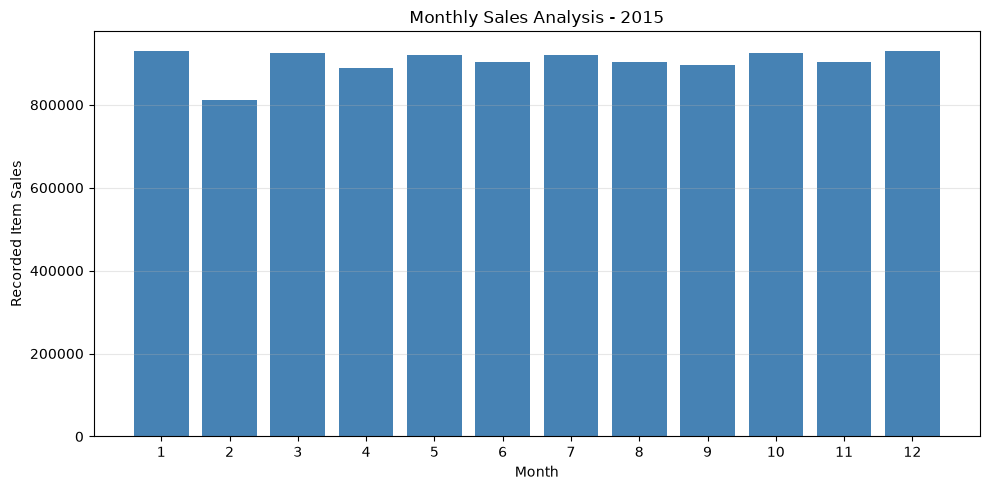

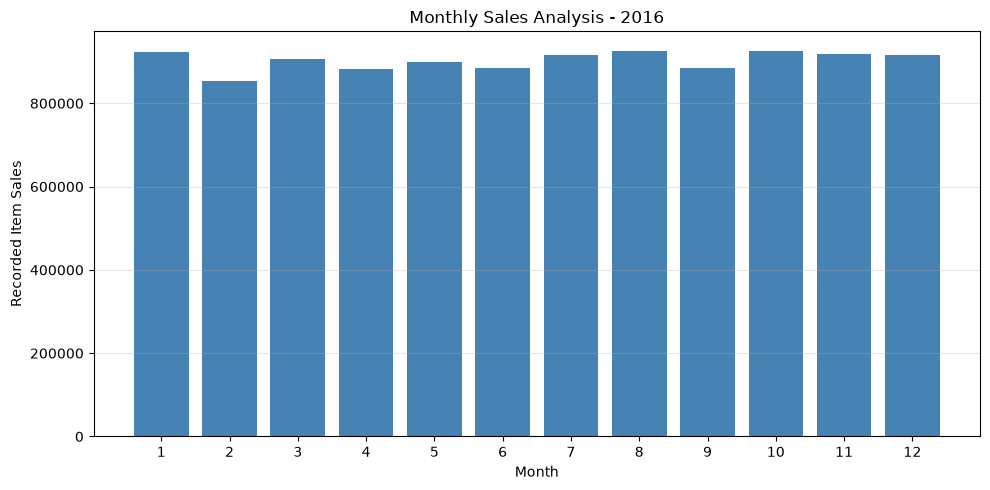

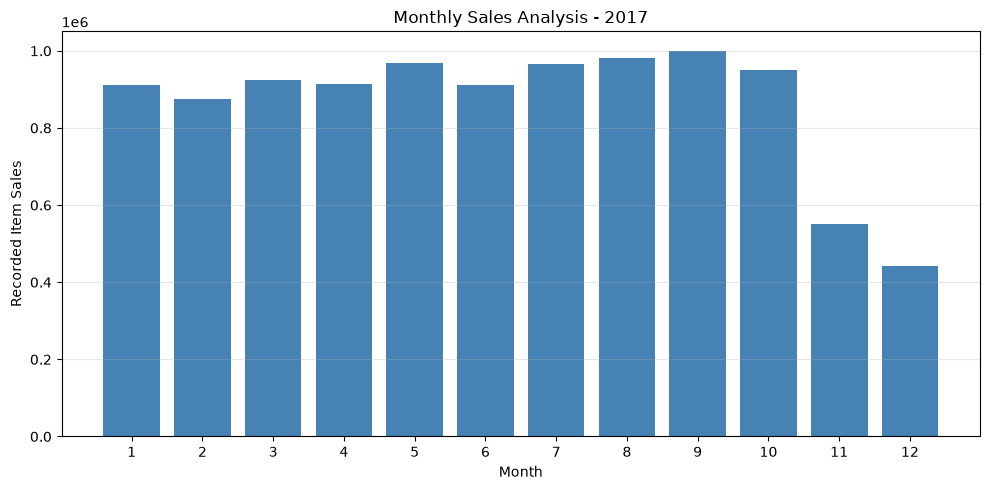

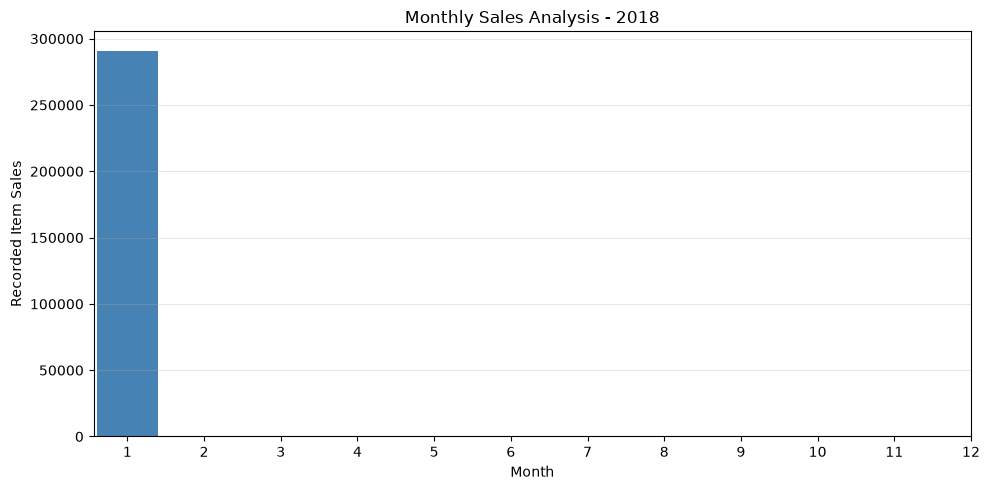

FINAL YEAR-WISE SALES COMPARISON


,total_sales,order_items,sales_growth_pct
Year,,,
2015,10859735.36,61339,NaN
2016,10838544.62,61302,-0.20
2017,10396867.83,52108,-4.08


In [3]:

# STEP 30: YEAR-WISE AND MONTHLY SALES ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Use the cleaned dataset already loaded as df
revenue_df = df.copy()

# Convert sales and date columns
revenue_df["Order Item Total"] = pd.to_numeric(
    revenue_df["Order Item Total"],
    errors="coerce"
)

revenue_df["order_date"] = pd.to_datetime(
    revenue_df["order date (DateOrders)"],
    format="mixed",
    errors="coerce"
)

# Exclude cancelled items, if cancellation flag exists
if "is_cancelled" in revenue_df.columns:
    cancelled = pd.to_numeric(
        revenue_df["is_cancelled"],
        errors="coerce"
    )
    revenue_df = revenue_df[cancelled == 0].copy()

revenue_df = revenue_df.dropna(
    subset=["order_date", "Order Item Total"]
)

# Order Item Total is at order-item level
# Avoid counting the same item more than once
if "Order Item Id" in revenue_df.columns:
    revenue_df = revenue_df.drop_duplicates(
        subset=["Order Item Id"]
    )

revenue_df["Year"] = revenue_df["order_date"].dt.year
revenue_df["Month"] = revenue_df["order_date"].dt.month

# YEARLY SALES
yearly_revenue = revenue_df.groupby("Year").agg(
    total_sales=("Order Item Total", "sum"),
    order_items=("Order Item Total", "size")
)

print("YEAR-WISE SALES ANALYSIS")
display(yearly_revenue.round(2))

# MONTHLY SALES
monthly_revenue = revenue_df.groupby(
    ["Year", "Month"]
)["Order Item Total"].sum().reset_index(
    name="total_sales"
)

print("MONTHLY SALES ANALYSIS")
display(monthly_revenue.round(2))

# Create output directory
output_dir = (
    Path(file_path).resolve().parents[2]
    / "EDA (Python-scripts)"
    / "visualizations"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Separate graph for each year
for year in sorted(monthly_revenue["Year"].unique()):

    data = monthly_revenue[
        monthly_revenue["Year"] == year
    ].sort_values("Month")

    plt.figure(figsize=(10, 5))

    plt.bar(
        data["Month"],
        data["total_sales"],
        color="steelblue"
    )

    plt.title(f"Monthly Sales Analysis - {year}")
    plt.xlabel("Month")
    plt.ylabel("Recorded Item Sales")
    plt.xticks(range(1, 13))
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        output_dir / f"monthly_sales_{year}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# Yearly sales comparison: complete years only
full_year_sales = yearly_revenue.reindex(
    [2015, 2016, 2017]
).dropna()

full_year_sales["sales_growth_pct"] = (
    full_year_sales["total_sales"].pct_change() * 100
)

print("FINAL YEAR-WISE SALES COMPARISON")
display(full_year_sales.round(2))


YEAR-WISE ORDER VALUE ANALYSIS


,total_sales,total_items,orders_with_sales,avg_sales_per_order,items_per_order,all_orders,orders_excluded
Year,,,,,,,
2015,10859735.36,61339,20463,530.70,3.00,20904,441
2016,10838544.62,61302,20428,530.57,3.00,20859,431
2017,10396867.83,52108,21416,485.47,2.43,21866,450


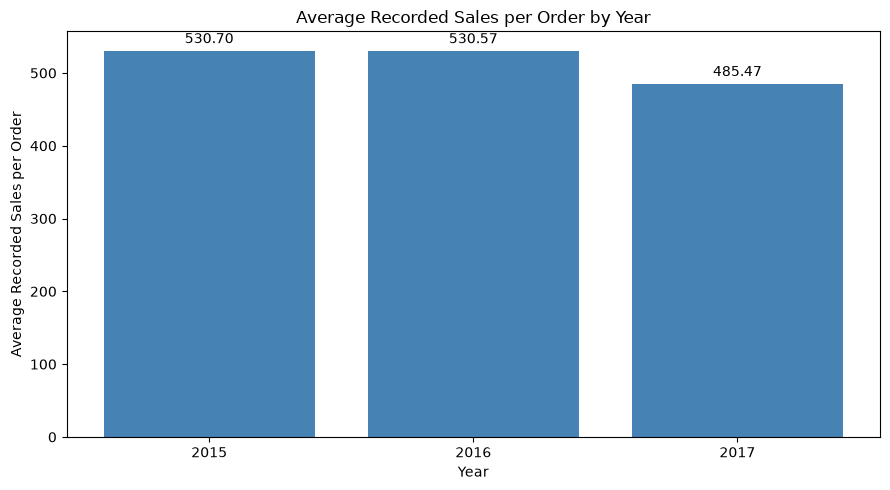

Year-wise order value analysis completed!


In [5]:

# STEP 31: YEAR-WISE ORDER VALUE ANALYSIS

# Analyze complete years only
financial_df = revenue_df[
    revenue_df["Year"].isin([2015, 2016, 2017])
].copy()

# Aggregate financial metrics by year
yearly_financial = financial_df.groupby("Year").agg(
    total_sales=("Order Item Total", "sum"),
    total_items=("Order Item Total", "size"),
    orders_with_sales=("Order Id", "nunique")
)

# Average recorded sales per order
yearly_financial["avg_sales_per_order"] = (
    yearly_financial["total_sales"] /
    yearly_financial["orders_with_sales"]
)

# Average number of items per order
yearly_financial["items_per_order"] = (
    yearly_financial["total_items"] /
    yearly_financial["orders_with_sales"]
)

# Compare with all orders from Step 25

# Calculate total unique orders directly from dataset
all_order_counts = (
    df.assign(
        Year=pd.to_datetime(
            df["order date (DateOrders)"],
            format="mixed",
            errors="coerce"
        ).dt.year
    )
    .groupby("Year")["Order Id"]
    .nunique()
)

yearly_financial["all_orders"] = (
    all_order_counts.reindex(yearly_financial.index)
)


yearly_financial["orders_excluded"] = (
    yearly_financial["all_orders"] -
    yearly_financial["orders_with_sales"]
)

print("YEAR-WISE ORDER VALUE ANALYSIS")
display(yearly_financial.round(2))

# Sales per order visualization
plt.figure(figsize=(9, 5))

bars = plt.bar(
    yearly_financial.index.astype(str),
    yearly_financial["avg_sales_per_order"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Average Recorded Sales per Order by Year")
plt.xlabel("Year")
plt.ylabel("Average Recorded Sales per Order")

plt.tight_layout()

plt.savefig(
    output_dir / "yearwise_average_order_value.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Year-wise order value analysis completed!")


YEAR-WISE PROFITABILITY INDICATORS


,total_records,negative_records,avg_benefit,median_benefit,negative_benefit_rate
Year,,,,,
2015,61339,11479,20.99,30.94,18.71
2016,61302,11563,20.93,30.91,18.86
2017,52108,9641,24.72,33.56,18.50


Orders with multiple benefit values: 44958


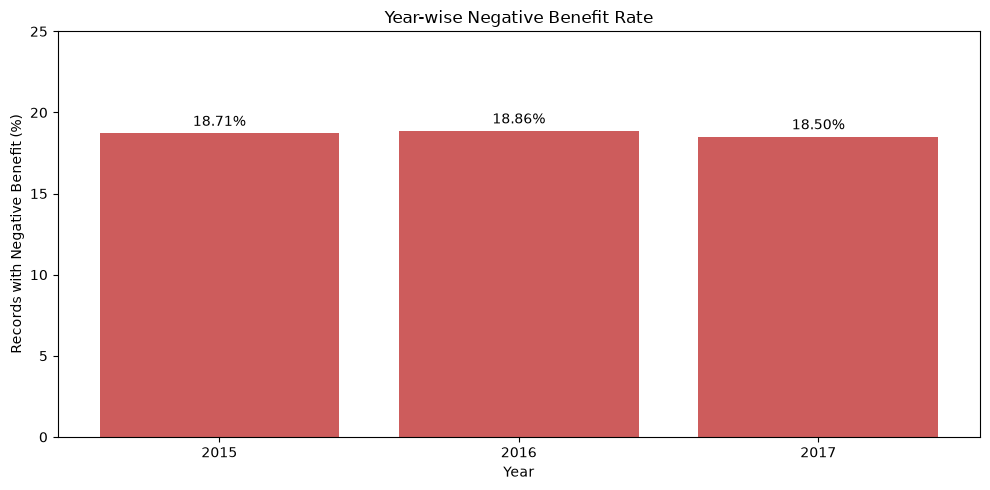

Year-wise profitability indicator analysis completed!


In [6]:

# STEP 32: YEAR-WISE PROFITABILITY INDICATORS

import pandas as pd
import matplotlib.pyplot as plt

# Use filtered financial dataset from Step 31
profit_df = financial_df.copy()

# Convert benefit column into numeric format
profit_df["benefit_value"] = pd.to_numeric(
    profit_df["Benefit per order"],
    errors="coerce"
)

profit_df = profit_df.dropna(subset=["benefit_value"])

# Calculate yearly profitability indicators
yearly_profit = profit_df.groupby("Year").agg(
    total_records=("benefit_value", "size"),
    negative_records=(
        "benefit_value",
        lambda x: (x < 0).sum()
    ),
    avg_benefit=("benefit_value", "mean"),
    median_benefit=("benefit_value", "median")
)

# Percentage of records with negative benefit
yearly_profit["negative_benefit_rate"] = (
    yearly_profit["negative_records"]
    / yearly_profit["total_records"] * 100
)

print("YEAR-WISE PROFITABILITY INDICATORS")
display(yearly_profit.round(2))

# Check whether benefit varies within the same order
benefit_per_order_variation = (
    profit_df.groupby("Order Id")["benefit_value"]
    .nunique()
)

print(
    "Orders with multiple benefit values:",
    (benefit_per_order_variation > 1).sum()
)

# Visualization
plt.figure(figsize=(10, 5))

bars = plt.bar(
    yearly_profit.index.astype(str),
    yearly_profit["negative_benefit_rate"],
    color="indianred"
)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=3
)

plt.title("Year-wise Negative Benefit Rate")
plt.xlabel("Year")
plt.ylabel("Records with Negative Benefit (%)")
plt.ylim(
    0,
    max(25, yearly_profit["negative_benefit_rate"].max() * 1.2)
)

plt.tight_layout()

plt.savefig(
    output_dir / "yearwise_negative_benefit_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Year-wise profitability indicator analysis completed!")


YEAR-WISE REGIONAL SALES


,Year,Order Region,total_sales,total_items,unique_orders
9,2015,Western Europe,2538025.21,14316,4732
1,2015,Central America,2424826.02,13675,4570
5,2015,South America,1299562.25,7390,2451
3,2015,Northern Europe,924588.02,5161,1765
8,2015,Southern Europe,869004.39,4970,1656
0,2015,Caribbean,732584.78,4128,1386
7,2015,Southeast Asia,643380.49,3619,1201
4,2015,Oceania,516316.57,2932,999
2,2015,Eastern Asia,507026.72,2866,954
6,2015,South Asia,404420.92,2282,749



TOP 10 REGIONS - YEAR-WISE SALES


Year,2015,2016,2017
Order Region,,,
Western Europe,2538025.21,26532.84,2625804.76
Central America,2424826.02,0.00,2573593.54
South America,1299562.25,0.00,1292544.34
Northern Europe,924588.02,16895.35,955490.29
Southern Europe,869004.39,28111.41,906297.30
Oceania,516316.57,1001010.98,181880.72
Southeast Asia,643380.49,709651.20,263268.41
Caribbean,732584.78,0.00,718550.06
West of USA,0.00,1382300.49,0.00



REGIONAL SALES GROWTH (2016-2017)


Year,2015,2016,2017,growth_2017_pct
Order Region,,,,
West of USA,0.00,1382300.49,0.00,-100.00
Oceania,516316.57,1001010.98,181880.72,-81.83
South Asia,404420.92,713707.11,183866.51,-74.24
Southeast Asia,643380.49,709651.20,263268.41,-62.90
Southern Europe,869004.39,28111.41,906297.30,3123.95
Northern Europe,924588.02,16895.35,955490.29,5555.34
Western Europe,2538025.21,26532.84,2625804.76,9796.43
Central America,2424826.02,0.00,2573593.54,NaN
South America,1299562.25,0.00,1292544.34,NaN


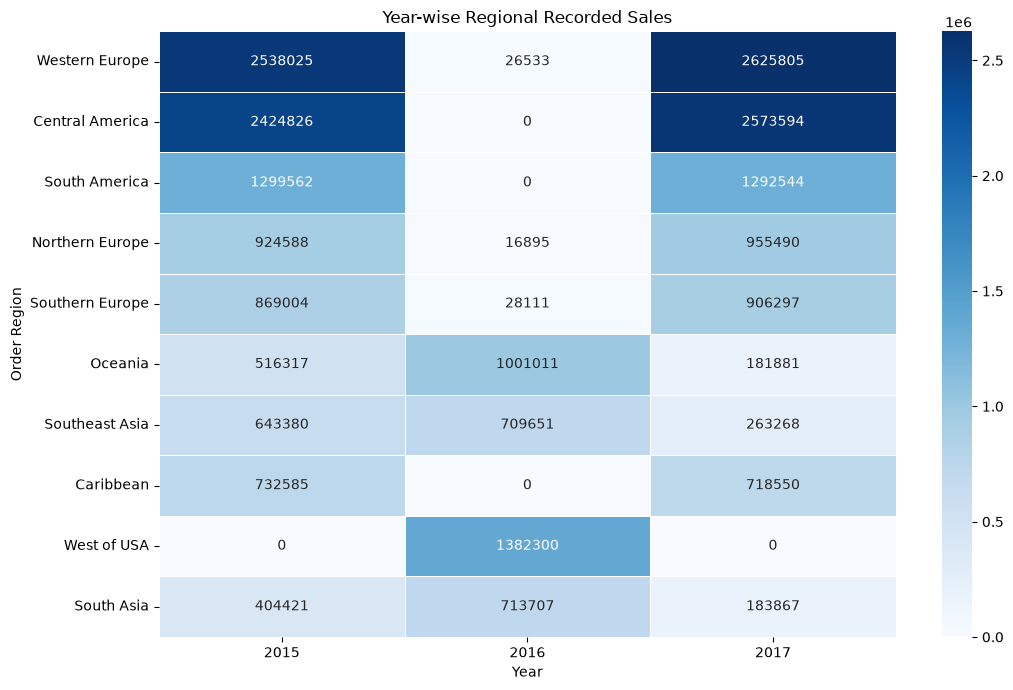

Regional sales analysis completed!


In [7]:

# STEP 33: YEAR-WISE REGIONAL SALES ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use item-level sales data from Step 31
regional_df = financial_df.copy()

# Remove records without a region
regional_df = regional_df.dropna(
    subset=["Order Region"]
)

# Calculate sales by year and region
regional_yearly = regional_df.groupby(
    ["Year", "Order Region"]
).agg(
    total_sales=("Order Item Total", "sum"),
    total_items=("Order Item Total", "size"),
    unique_orders=("Order Id", "nunique")
).reset_index()

print("YEAR-WISE REGIONAL SALES")
display(
    regional_yearly.sort_values(
        ["Year", "total_sales"],
        ascending=[True, False]
    ).round(2)
)

# Find top 10 regions by total recorded sales
top_regions = (
    regional_yearly.groupby("Order Region")["total_sales"]
    .sum()
    .nlargest(10)
    .index
)

# Prepare year-wise comparison
regional_pivot = (
    regional_yearly[
        regional_yearly["Order Region"].isin(top_regions)
    ]
    .pivot(
        index="Order Region",
        columns="Year",
        values="total_sales"
    )
    .reindex(top_regions)
    .fillna(0)
)

print("\nTOP 10 REGIONS - YEAR-WISE SALES")
display(regional_pivot.round(2))

# Percentage change: 2016 to 2017
regional_growth = regional_pivot.copy()

regional_growth["growth_2017_pct"] = (
    (regional_growth[2017] - regional_growth[2016])
    / regional_growth[2016].replace(0, float("nan"))
    * 100
)

print("\nREGIONAL SALES GROWTH (2016-2017)")
display(
    regional_growth.sort_values(
        "growth_2017_pct"
    ).round(2)
)

# Heatmap visualization
plt.figure(figsize=(11, 7))

sns.heatmap(
    regional_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Year-wise Regional Recorded Sales")
plt.xlabel("Year")
plt.ylabel("Order Region")

plt.tight_layout()

plt.savefig(
    output_dir / "yearwise_regional_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Regional sales analysis completed!")


In [8]:

# STEP 34: VERIFY YEAR-WISE REGIONAL DATA

import pandas as pd

# Check original cleaned dataset
check_df = df.copy()

check_df["Year"] = pd.to_datetime(
    check_df["order date (DateOrders)"],
    format="mixed",
    errors="coerce"
).dt.year

# Normalize region labels
check_df["Order Region"] = (
    check_df["Order Region"].astype("string").str.strip()
)

# Count records in original cleaned dataset
raw_check = (
    check_df[
        check_df["Year"].isin([2015, 2016, 2017])
    ]
    .groupby(["Year", "Order Region"])
    .agg(
        raw_records=("Order Id", "size"),
        raw_orders=("Order Id", "nunique")
    )
    .reset_index()
)

# Check sales records after financial filtering
sales_check = financial_df.copy()

sales_check["Order Region"] = (
    sales_check["Order Region"].astype("string").str.strip()
)

filtered_check = (
    sales_check.groupby(["Year", "Order Region"])
    .agg(
        sales_records=("Order Id", "size"),
        sales_orders=("Order Id", "nunique"),
        recorded_sales=("Order Item Total", "sum")
    )
    .reset_index()
)

# Compare raw and filtered data
verification = raw_check.merge(
    filtered_check,
    on=["Year", "Order Region"],
    how="outer"
)

# Focus on regions with unusual patterns
focus_regions = [
    "Western Europe",
    "Central America",
    "Oceania",
    "Southeast Asia",
    "West of USA"
]

result = verification[
    verification["Order Region"].isin(focus_regions)
].sort_values(["Order Region", "Year"])

print("REGIONAL DATA VERIFICATION")
display(result.round(2))

print("Verification completed!")


REGIONAL DATA VERIFICATION


,Year,Order Region,raw_records,raw_orders,sales_records,sales_orders,recorded_sales
1,2015,Central America,13957,4664,13675,4570,2424826.02
33,2017,Central America,14384,4732,14130,4642,2573593.54
4,2015,Oceania,2998,1021,2932,999,516316.57
19,2016,Oceania,5714,1905,5627,1873,1001010.98
40,2017,Oceania,883,883,867,867,181880.72
7,2015,Southeast Asia,3713,1233,3619,1201,643380.49
22,2016,Southeast Asia,4077,1374,3995,1347,709651.20
43,2017,Southeast Asia,1099,1099,1070,1070,263268.41
28,2016,West of USA,7993,2667,7831,2614,1382300.49
9,2015,Western Europe,14596,4828,14316,4732,2538025.21


Verification completed!


VERIFIED REGIONAL SALES COMPARISON


Year,2015,2016,2017
Order Region,,,
Western Europe,2538025.21,26532.84,2625804.76
Central America,2424826.02,NaN,2573593.54
South America,1299562.25,NaN,1292544.34
Northern Europe,924588.02,16895.35,955490.29
Southern Europe,869004.39,28111.41,906297.30
Oceania,516316.57,1001010.98,181880.72
Southeast Asia,643380.49,709651.20,263268.41
Caribbean,732584.78,NaN,718550.06
West of USA,NaN,1382300.49,NaN



REGIONAL DATA QUALITY CHECK


,Year,Order Region,raw_orders,sales_orders,rows_per_order,recorded_sales
1,2015,Central America,4664,4570,2.99,2424826.02
33,2017,Central America,4732,4642,3.04,2573593.54
4,2015,Oceania,1021,999,2.94,516316.57
19,2016,Oceania,1905,1873,3.00,1001010.98
40,2017,Oceania,883,867,1.00,181880.72
7,2015,Southeast Asia,1233,1201,3.01,643380.49
22,2016,Southeast Asia,1374,1347,2.97,709651.20
43,2017,Southeast Asia,1099,1070,1.00,263268.41
28,2016,West of USA,2667,2614,3.00,1382300.49
9,2015,Western Europe,4828,4732,3.02,2538025.21


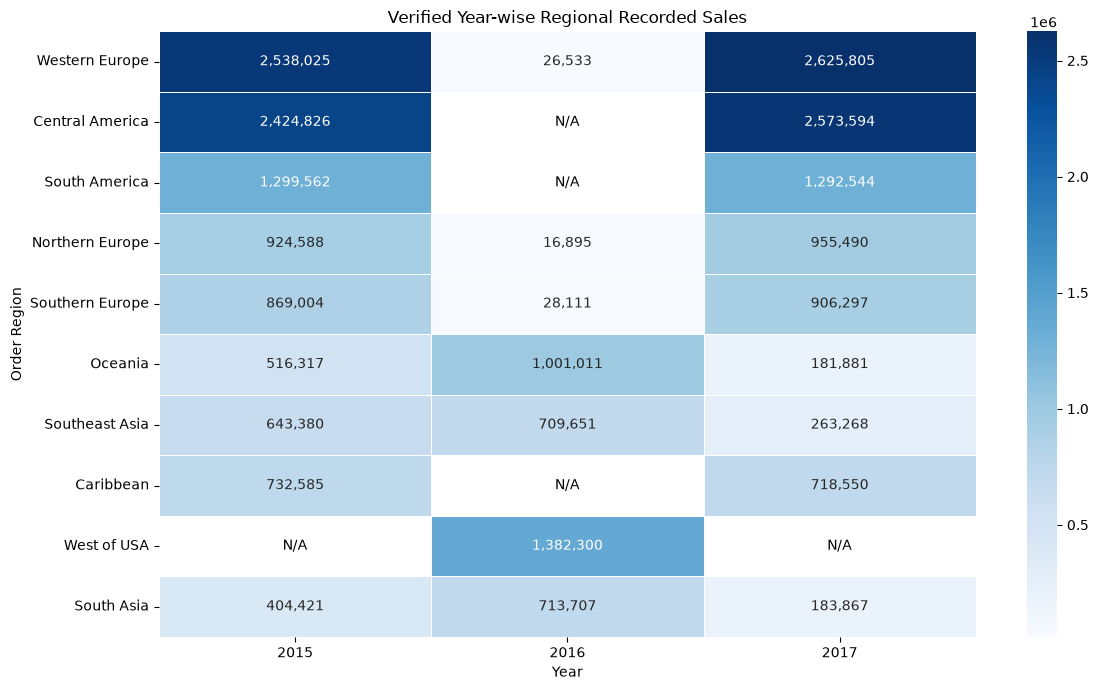

Corrected regional heatmap saved successfully!


In [9]:

# STEP 35: CORRECT REGIONAL SALES VISUALIZATION

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Keep missing region-year combinations as NaN
corrected_pivot = (
    regional_yearly[
        regional_yearly["Order Region"].isin(top_regions)
    ]
    .pivot(
        index="Order Region",
        columns="Year",
        values="total_sales"
    )
    .reindex(index=top_regions, columns=[2015, 2016, 2017])
)

print("VERIFIED REGIONAL SALES COMPARISON")
display(corrected_pivot.round(2))

# Check record granularity by region and year
quality_check = verification.copy()

quality_check["rows_per_order"] = (
    quality_check["raw_records"] /
    quality_check["raw_orders"]
)

print("\nREGIONAL DATA QUALITY CHECK")
display(
    quality_check[
        quality_check["Order Region"].isin(focus_regions)
    ][[
        "Year", "Order Region",
        "raw_orders", "sales_orders",
        "rows_per_order", "recorded_sales"
    ]].sort_values(
        ["Order Region", "Year"]
    ).round(2)
)

# Correct heatmap: missing values are not zero sales
plt.figure(figsize=(12, 7))

ax = sns.heatmap(
    corrected_pivot,
    mask=corrected_pivot.isna(),
    annot=True,
    fmt=",.0f",
    cmap="Blues",
    linewidths=0.5
)

# Clearly mark unavailable region-year data
for i, region in enumerate(corrected_pivot.index):
    for j, year in enumerate(corrected_pivot.columns):
        if pd.isna(corrected_pivot.loc[region, year]):
            ax.text(
                j + 0.5,
                i + 0.5,
                "N/A",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Verified Year-wise Regional Recorded Sales")
plt.xlabel("Year")
plt.ylabel("Order Region")
plt.tight_layout()

plt.savefig(
    output_dir / "yearwise_regional_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Corrected regional heatmap saved successfully!")


In [10]:

# STEP 36: GENERATE FINANCIAL EDA DOCUMENTATION

from pathlib import Path

eda_dir = Path(output_dir).resolve().parent

findings_path = eda_dir / "EDA_Findings.md"
readme_path = eda_dir / "README.md"

# Financial summary table
rows = []

for year in [2015, 2016, 2017]:
    f = yearly_financial.loc[year]
    p = yearly_profit.loc[year]

    rows.append(
        f"| {year} "
        f"| {f['total_sales']:,.2f} "
        f"| {int(f['all_orders']):,} "
        f"| {f['avg_sales_per_order']:.2f} "
        f"| {f['items_per_order']:.2f} "
        f"| {p['negative_benefit_rate']:.2f}% |"
    )

financial_table = "\n".join(rows)

# Financial findings for existing report
financial_report = f"""
## 12. Year-wise Financial Performance Analysis

The analysis uses recorded order-item sales values.
These figures are not independently verified net revenue.

| Year | Recorded Sales | All Orders | Avg Sales/Order | Item Lines/Order | Negative Benefit Rate |
|------|---------------:|-----------:|----------------:|-----------------:|----------------------:|
{financial_table}

### Key Findings

1. Recorded sales decreased by 4.08% in 2017
   compared with 2016.

2. Average recorded sales per order declined
   from 530.57 in 2016 to 485.47 in 2017.

3. Order volume increased by 4.83% in 2017,
   while recorded sales decreased.

4. Item lines per order declined from approximately
   3.00 to 2.43.

5. Negative-benefit record rates remained
   between 18.50% and 18.86%.

### Important Limitations

- Sales values are based on Order Item Total.
- Some orders were excluded from sales calculations.
- Benefit per order varies within many orders.
- Negative-benefit rates are record-level indicators.
- Currency, refunds and accounting revenue require
  independent verification.

## 13. Regional Sales Analysis

### Findings

- Western Europe has unusually low recorded
  sales and order coverage in 2016.
- Central America has no available 2016 records.
- Oceania recorded lower sales in 2017 than 2016.
- Southeast Asia also recorded lower sales in 2017.
- West of USA records appear only in 2016.

### Data Quality Notes

Missing region-year combinations are marked N/A,
not zero sales.

Regional comparisons may be affected by changes
in data coverage and order-item granularity.

Regional changes should not automatically be
interpreted as business growth or decline.

## 14. Financial Business Problem

How can the business improve recorded sales per
order and delivery reliability while investigating
financial performance and regional data quality?

### Recommendations

1. Monitor average sales per order every month.
2. Investigate the reduction in item lines per order.
3. Analyze product categories with negative benefit.
4. Review shipping performance and delivery delays.
5. Validate regional data coverage before comparison.
6. Investigate changes in customer purchasing patterns.
7. Verify sales and profitability metric definitions.
"""

# Prevent duplicate financial report sections
marker = "## 12. Year-wise Financial Performance Analysis"

if findings_path.exists():
    existing = findings_path.read_text(encoding="utf-8")
else:
    existing = "# EDA Findings\n"

if marker in existing:
    existing = existing.split(marker)[0]

findings_path.write_text(
    existing.rstrip() + "\n\n" +
    financial_report.strip() + "\n",
    encoding="utf-8"
)

# README overview
chart_count = len(list(output_dir.glob("*.png")))

readme = f"""# Exploratory Data Analysis (EDA)

## Project
E-Commerce Delivery and Logistics Performance Analysis

## Overview
This folder contains exploratory analysis of order
activity, delivery performance, sales indicators,
customer behavior, profitability indicators,
and regional performance.

## Analysis Completed

- Data overview and quality verification
- Shipping and delivery performance
- Monthly and yearly order trends
- Customer purchasing patterns
- Product category sales analysis
- Negative-benefit record analysis
- Year-wise recorded sales trends
- Average recorded sales per order
- Regional sales and coverage verification
- Correlation and redundancy analysis

## Key Findings

- Late delivery rate exceeded 56% in each
  complete year from 2015 to 2017.
- Recorded sales decreased by 4.08% in 2017.
- Average recorded sales per order fell from
  530.57 in 2016 to 485.47 in 2017.
- Regional reporting coverage differs by year.
- Financial figures are exploratory indicators,
  not verified net revenue or accounting profit.

## Files

- delivery_eda.ipynb: Python analysis notebook
- EDA_Findings.md: Detailed findings and limitations
- visualizations/: {chart_count} PNG graphs

## Tools
Python, Pandas, NumPy, Matplotlib and Seaborn

## Data Notes
The 2018 dataset covers only January.
Financial and regional comparisons require careful
interpretation due to coverage and metric limitations.
"""

readme_path.write_text(readme, encoding="utf-8")

print("Financial EDA documentation completed!")
print("Findings:", findings_path)
print("README:", readme_path)
print("Total PNG charts:", chart_count)


Financial EDA documentation completed!
Findings: C:\Users\Admin\Downloads\E-Commerce and Logistics delivery Analysis\E-Commerce and Logistics delivery Analysis\EDA (Python-scripts)\EDA_Findings.md
README: C:\Users\Admin\Downloads\E-Commerce and Logistics delivery Analysis\E-Commerce and Logistics delivery Analysis\EDA (Python-scripts)\README.md
Total PNG charts: 27
